# Online Appendix: EmbeddingGemma 2 with and without Fine-Tuning

Writes `Appendix_Gemma.tex`, Section 7 of the Online Appendix, from `templates/Appendix_Gemma.tex`. The text of Section 7.1 (off-the-shelf EmbeddingGemma 2) is that of the paper version of October 2026 (generated by `gemma/code/05_appendix_gemma.ipynb`, then edited by hand); its tables are extended by the fine-tuned EmbeddingGemma 2 of this folder. Section 7.2 (fine-tuned EmbeddingGemma 2) is generated here. All tables and numbers are read from the outputs of the executed notebooks, and the qualitative statements of Section 7.2 are checked with assertions:

| content | source |
| --- | --- |
| fine-tuning | `../data/finetuned/<modality>/{config,history}_<modality>.json`, `../data/finetuned/txtimg/predictions_txtimg.parquet`; network of the main analysis: `pred_ml_l`, `pred_ml_m` in `main/data/dataset_txt_only_False_embeddings_True_{train,val}.zip` |
| predictive performance (test $R^2$) | `03_1_predictive_performance_txt_img.ipynb` in `main/code`, `gemma/code` and this folder |
| homogeneous elasticities, $\chi^2$ tests, sorted effects, sensitivity analysis | outputs of `04_evaluation.ipynb` for the five runs of `04_evaluation_comparison.ipynb` and the two off-the-shelf variants in `gemma/outputs/04_evaluation_comparison/gemma_*` |

The figures `ate_estimates_comparison_finetuned.png` and `sorted_effects_comparison_finetuned.png` are those of `04_evaluation_comparison.ipynb` with the legend labels of the Online Appendix, where the main analysis is labelled "Fine-tuned" as in the figures of Section 7.1.

Outputs: `../outputs/05_appendix_gemma_tuned/Appendix_Gemma.tex` and `figures/`. Requires `03_1`, `04_evaluation` (all runs) and `04_evaluation_comparison` of this folder and of `gemma/code`. Run from `Gemma-tuned/code`.

In [1]:
import os
import re
import json
import shutil
from html.parser import HTMLParser
from pathlib import Path

import numpy as np
import pandas as pd
import nbformat
import matplotlib.pyplot as plt
import seaborn as sns

# Parameters
output_dir = "../outputs/05_appendix_gemma_tuned"
paper_figure_dir = "paper/figures_revision/gemma"  # figure path used in Appendix_Gemma.tex (Overleaf project)

main_dir = "../../main/output/04_evaluation"
run_dirs = {
    "main": "../../gemma/outputs/04_evaluation_comparison/finetuned",  # fine-tuned embeddings of the main analysis (re-run)
    "gemma": "../../gemma/outputs/04_evaluation",
    "gemma_txt": "../../gemma/outputs/04_evaluation_comparison/gemma_txt_dim256",
    "gemma_768": "../../gemma/outputs/04_evaluation_comparison/gemma_txtimg_dim768",
    "tuned": "../outputs/04_evaluation",
    "tuned_txt": "../outputs/04_evaluation_comparison/tuned_txt_dim256",
    "tuned_768": "../outputs/04_evaluation_comparison/tuned_txtimg_dim768",
}
Path(output_dir, "figures").mkdir(parents=True, exist_ok=True)

## Inputs and consistency checks

In [2]:
# fine-tuning: configuration, selected epochs and loss L on all product-period rows of I_2
cfg = {m: json.load(open(f"../data/finetuned/{m}/config_{m}.json"))["config"] for m in ["txtimg", "txt"]}
hist = {m: json.load(open(f"../data/finetuned/{m}/history_{m}.json")) for m in ["txtimg", "txt"]}
for m in cfg:
    assert cfg[m]["modality"] == m and cfg[m]["emb_dim"] == 256 and cfg[m]["lora_r"] == 16 and cfg[m]["max_epochs"] == 20
    best = min(hist[m]["history"], key=lambda e: e["val_loss"])
    assert best["epoch"] == hist[m]["best_epoch"] and np.isclose(best["val_loss"], hist[m]["best_val_loss"], rtol=0, atol=1e-12)
assert cfg["txtimg"]["lora_vision"]


def loss(y_q, y_p, f_q, f_p):
    # loss L of step 2 of the workflow: RMSE(Q) * RMSE(P)
    return np.sqrt(np.mean((y_q - f_q) ** 2)) * np.sqrt(np.mean((y_p - f_p) ** 2))


cols = ["ASIN", "date", "Q_t", "P_bb_t", "pred_ml_l", "pred_ml_m"]
main_train = pd.read_csv("../../main/data/dataset_txt_only_False_embeddings_True_train.zip", usecols=cols)
main_val = pd.read_csv("../../main/data/dataset_txt_only_False_embeddings_True_val.zip", usecols=cols)
pred_tuned = pd.read_parquet("../data/finetuned/txtimg/predictions_txtimg.parquet")
val = main_val.assign(date=main_val["date"].astype(str)).merge(
    pred_tuned.assign(date=pred_tuned["date"].astype(str))[["ASIN", "date", "pred_ml_l", "pred_ml_m"]],
    on=["ASIN", "date"], how="left", suffixes=("", "_tuned"), validate="one_to_one",
)
assert val[["pred_ml_l_tuned", "pred_ml_m_tuned"]].notna().all().all()
assert len(val) == (pred_tuned["split"] == "val").sum()
y_q, y_p = val["Q_t"].values, val["P_bb_t"].values
fit = {
    "tuned": loss(y_q, y_p, val["pred_ml_l_tuned"].values, val["pred_ml_m_tuned"].values),
    "main": loss(y_q, y_p, val["pred_ml_l"].values, val["pred_ml_m"].values),
    "constant": loss(y_q, y_p, main_train["Q_t"].mean(), main_train["P_bb_t"].mean()),  # means over I_1
}
# the network of the main analysis was selected by the same loss on I_2 (file name of its checkpoint)
assert "time_independent_txtimg_mod4-epoch=023-val_combined_loss=0.3322" in open("../../main/code/utils/paths_config.yaml").read()
assert abs(fit["main"] - 0.3322) < 5e-5
assert abs(fit["tuned"] - hist["txtimg"]["best_val_loss"]) < 1e-3
print(f"I_2: {len(val):,} rows, {val['ASIN'].nunique():,} products;", {k: round(v, 4) for k, v in fit.items()})
print({m: (hist[m]["best_epoch"], round(hist[m]["best_val_loss"], 4)) for m in hist})

I_2: 41,832 rows, 3,775 products; {'tuned': np.float64(0.2966), 'main': np.float64(0.3322), 'constant': np.float64(0.8179)}
{'txtimg': (20, 0.2966), 'txt': (19, 0.3191)}


In [3]:
class _TableParser(HTMLParser):
    # Minimal parser for the HTML representation of a pandas DataFrame.

    def __init__(self):
        super().__init__()
        self.rows, self._row, self._cell = [], None, None

    def handle_starttag(self, tag, attrs):
        if tag == "tr":
            self._row = []
        elif tag in ("td", "th") and self._row is not None:
            self._cell = ""

    def handle_endtag(self, tag):
        if tag in ("td", "th") and self._cell is not None:
            self._row.append(self._cell.strip())
            self._cell = None
        elif tag == "tr" and self._row is not None:
            self.rows.append(self._row)
            self._row = None

    def handle_data(self, data):
        if self._cell is not None:
            self._cell += data


def read_result_table(notebook, variable):
    # Read the DataFrame displayed by the cell `<variable> = pd.concat(...)` of an executed notebook.
    nb = nbformat.read(notebook, as_version=4)
    cells = [c for c in nb.cells if c.cell_type == "code" and re.match(rf"{variable} = pd\.concat", c.source.strip())]
    assert len(cells) == 1, (notebook, variable)
    html = [o["data"]["text/html"] for o in cells[0].outputs if "data" in o and "text/html" in o["data"]]
    assert len(html) == 1
    parser = _TableParser()
    parser.feed(html[0])
    header, *body = parser.rows
    return pd.DataFrame([r[1:] for r in body], index=[r[0] for r in body], columns=header[1:]).astype(float)


r2 = {}
for label, notebook in [
    ("main", "../../main/code/03_1_predictive_performance_txt_img.ipynb"),
    ("gemma", "../../gemma/code/03_1_predictive_performance_txt_img.ipynb"),
    ("tuned", "03_1_predictive_performance_txt_img.ipynb"),
]:
    levels = read_result_table(notebook, "results_df")
    diffs = read_result_table(notebook, "results_df_diff")
    r2[label] = pd.DataFrame(
        {"Q": levels["R2 Q Test"], "P": levels["R2 P Test"], "dQ": diffs["R2 Q Test"], "dP": diffs["R2 P Test"]}
    )
# the benchmarks without embeddings and the network of the main analysis do not depend on the embeddings
for row in ["OLS (Tabular)", "Boosting (Tabular)", "Deep Time Independent"]:
    for label in ["gemma", "tuned"]:
        assert np.allclose(r2["main"].loc[row], r2[label].loc[row], rtol=0, atol=1e-12), (row, label)
pd.concat(r2, axis=1).round(4)

main                           gemma  \
                                          Q       P      dQ      dP       Q   
OLS (Tabular)                        0.2084  0.1582  0.0708  0.0064  0.2084   
Boosting (Tabular)                   0.4751  0.1854  0.1513 -0.0043  0.4751   
OLS (Tabular + PCA)                  0.4647  0.6063  0.0706  0.0064  0.3105   
Boosting (Tabular + PCA)             0.5322  0.6436  0.1379 -0.0045  0.5464   
OLS (Tabular + Similarities)         0.4727  0.5702  0.0707  0.0064  0.3030   
Boosting (Tabular + Similarities)    0.5258  0.6253  0.1463 -0.0024  0.5320   
OLS (Tabular + Embeddings)           0.5124  0.6214  0.0547 -0.0027  0.4088   
Boosting (Tabular + Embeddings)      0.5528  0.6564  0.1011 -0.0119  0.5877   
Deep Time Independent                0.5044  0.6726  0.1089  0.0115  0.5044   
Deep Time Dependent                  0.5953  0.6669  0.1217  0.0165  0.5953   
Fine-tuned EmbeddingGemma 2 (heads)     NaN     NaN     NaN     NaN     NaN   

                                                              tuned          \
                                          P      dQ      dP       Q       P   
OLS (Tabular)                        0.1582  0.0708  0.0064  0.2084  0.1582   
Boosting (Tabular)                   0.1854  0.1513 -0.0043  0.4751  0.1854   
OLS (Tabular + PCA)                  0.1650  0.0709  0.0067  0.4816  0.7031   
Boosting (Tabular + PCA)             0.3756  0.1707  0.0047  0.5442  0.7267   
OLS (Tabular + Similarities)         0.1680  0.0709  0.0066  0.2730  0.6943   
Boosting (Tabular + Similarities)    0.3222  0.1680  0.0054  0.5205  0.7178   
OLS (Tabular + Embeddings)           0.5230  0.0707  0.0055  0.5220  0.7261   
Boosting (Tabular + Embeddings)      0.5554  0.1836  0.0156  0.5557  0.7162   
Deep Time Independent                0.6726  0.1089  0.0115  0.5044  0.6726   
Deep Time Dependent                  0.6669  0.1217  0.0165  0.5953  0.6669   
Fine-tuned EmbeddingGemma 2 (heads)     NaN     NaN     NaN  0.5000  0.7419   

                                                     
                                         dQ      dP  
OLS (Tabular)                        0.0708  0.0064  
Boosting (Tabular)                   0.1513 -0.0043  
OLS (Tabular + PCA)                  0.0708  0.0067  
Boosting (Tabular + PCA)             0.1655  0.0079  
OLS (Tabular + Similarities)         0.0708  0.0066  
Boosting (Tabular + Similarities)    0.1719  0.0041  
OLS (Tabular + Embeddings)           0.0722  0.0046  
Boosting (Tabular + Embeddings)      0.1839  0.0189  
Deep Time Independent                0.1089  0.0115  
Deep Time Dependent                  0.1217  0.0165  
Fine-tuned EmbeddingGemma 2 (heads)     NaN     NaN

In [4]:
# estimation outputs (04_evaluation) of all runs
ate, hom, chi2, key, sorted_effects = {}, {}, {}, {}, {}
for run, d in run_dirs.items():
    lin = pd.read_csv(os.path.join(d, "linear_ate_estimates.csv"))
    plr = pd.read_csv(os.path.join(d, "plr_ate_estimates.csv"))
    ate[run] = pd.concat([lin, plr]).set_index("model")
    hom[run] = pd.read_csv(os.path.join(d, "homogeneous_elasticity_estimates.csv"), index_col=0)
    chi2[run] = pd.read_csv(os.path.join(d, "chi2_tests.csv")).set_index("model")
    key[run] = json.load(open(os.path.join(d, "key_results.json")))["sensitivity"]
    sorted_effects[run] = pd.read_csv(os.path.join(d, "sorted_effects.csv"))
    assert sorted_effects[run][["ASIN", "date"]].equals(sorted_effects["main"][["ASIN", "date"]]), run

# the re-run of the main specification reproduces main/output/04_evaluation
for file_name in ["homogeneous_elasticity_estimates.csv", "sensitivity_calibrated.csv", "sensitivity_robustness_values.csv"]:
    a = pd.read_csv(os.path.join(main_dir, file_name)).select_dtypes("number")
    b = pd.read_csv(os.path.join(run_dirs["main"], file_name)).select_dtypes("number")
    assert np.allclose(a.values, b.values, rtol=0, atol=1e-9), file_name

# sensitivity analysis at the residual shares of the main analysis
sens = {"main": pd.read_csv(os.path.join(main_dir, "sensitivity_calibrated.csv"))}
for run in ["gemma", "tuned", "tuned_txt", "tuned_768"]:
    sens[run] = pd.read_csv(os.path.join(run_dirs[run], "sensitivity_main_shares.csv"))
    assert np.allclose(sens[run]["share"], sens["main"]["share"], rtol=0, atol=0)
    assert np.allclose(sens[run]["theta"], ate[run].loc["plr_embeddings_add_controls", "coef"], rtol=0, atol=1e-12)

# the estimates equal the table written by 04_evaluation_comparison.ipynb
cmp = pd.read_csv("../outputs/04_evaluation_comparison/ate_estimates.csv", index_col=0)
cmp_labels = {
    "main": "DoubleMLDeep (txt+img, 256d)",
    "gemma": "EmbeddingGemma 2 (txt+img, 256d)",
    "tuned": "Fine-tuned EmbeddingGemma 2 (txt+img, 256d)",
    "tuned_txt": "Fine-tuned EmbeddingGemma 2 (txt, 256d)",
    "tuned_768": "Fine-tuned EmbeddingGemma 2 (txt+img, 768d)",
}
for run, label in cmp_labels.items():
    for model, value in cmp[label].items():
        r = ate[run].loc[model]
        assert value == f"{r['coef']:.3f} [{r['lower']:.3f}, {r['upper']:.3f}]", (run, model)
print("inputs consistent")

inputs consistent


## Figures

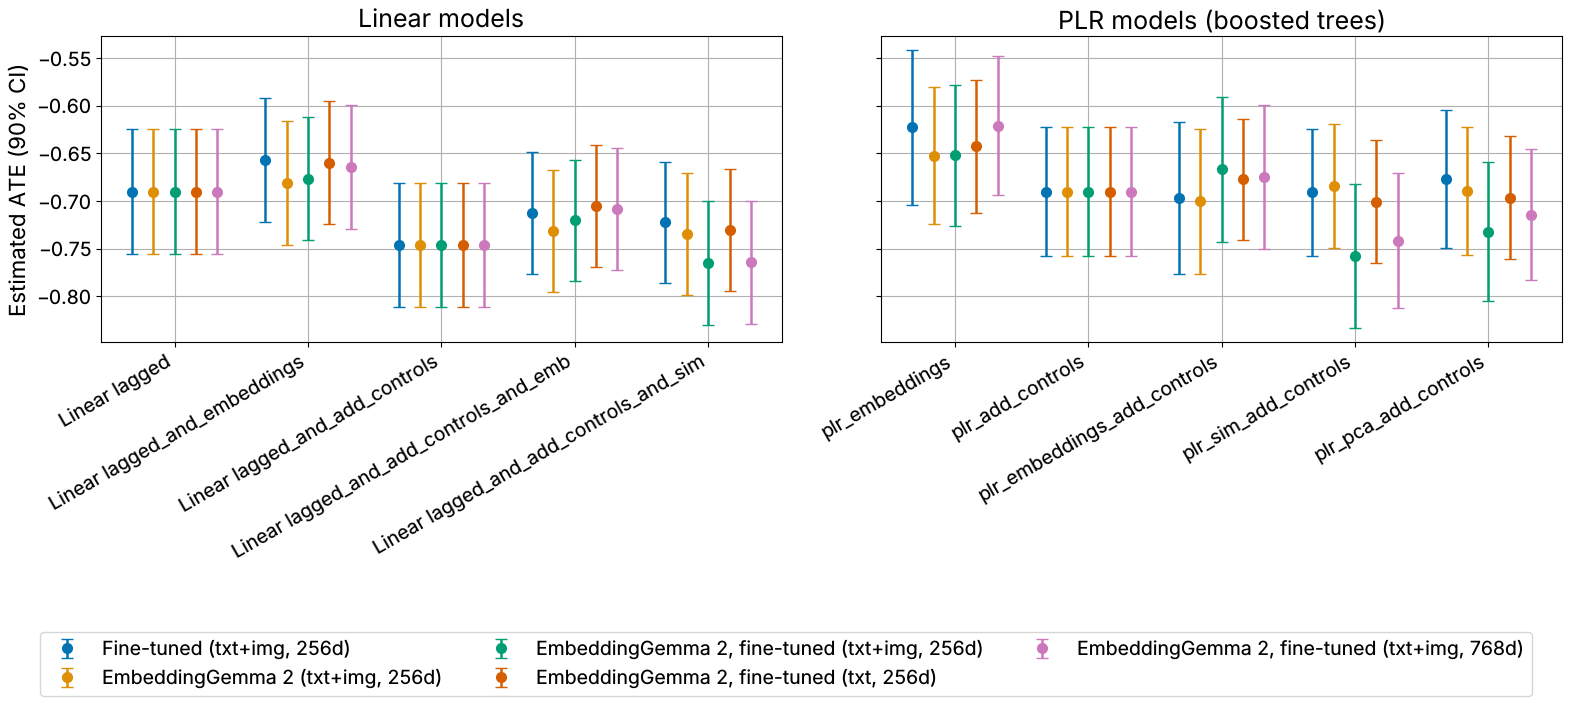

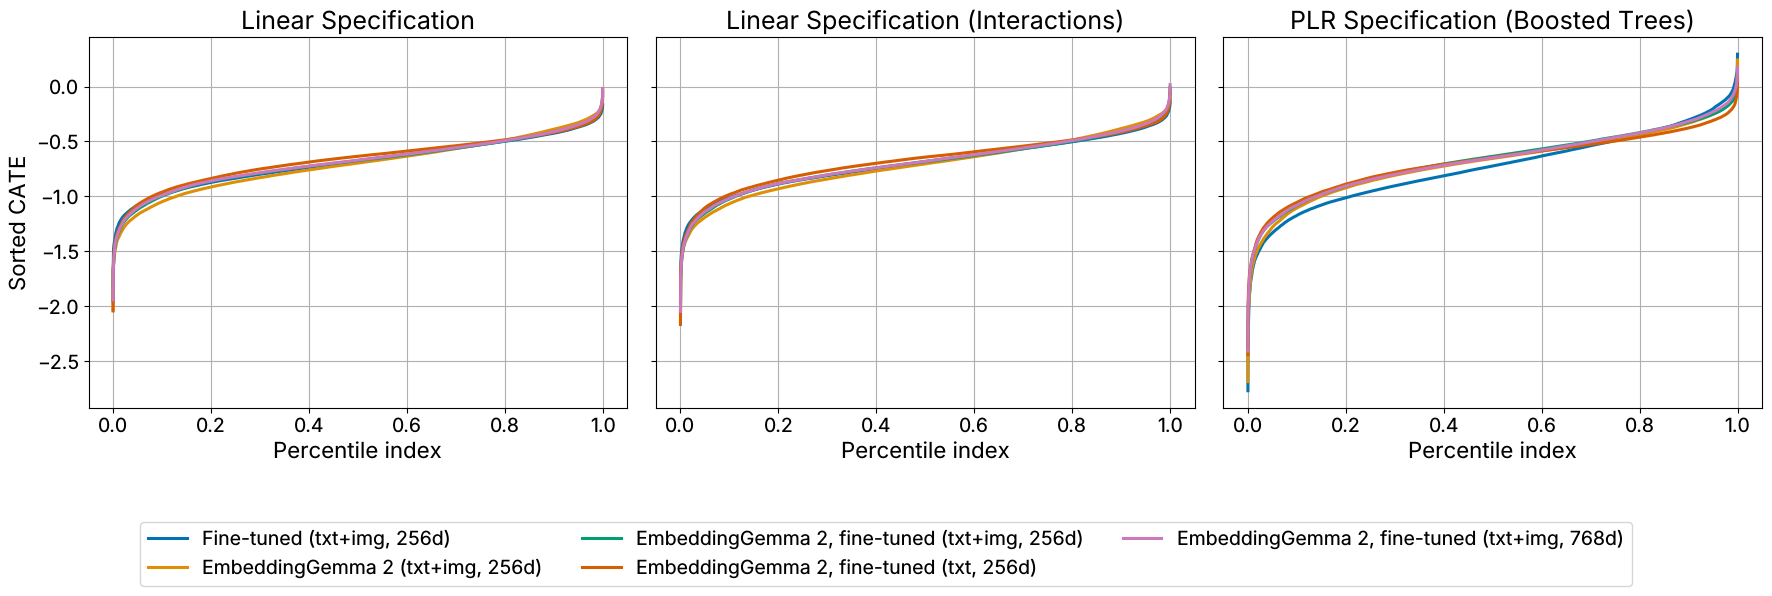

In [5]:
# figures of 04_evaluation_comparison.ipynb with the labels of the Online Appendix
palette = sns.color_palette("colorblind")
runs = {
    "main": "Fine-tuned (txt+img, 256d)",
    "gemma": "EmbeddingGemma 2 (txt+img, 256d)",
    "tuned": "EmbeddingGemma 2, fine-tuned (txt+img, 256d)",
    "tuned_txt": "EmbeddingGemma 2, fine-tuned (txt, 256d)",
    "tuned_768": "EmbeddingGemma 2, fine-tuned (txt+img, 768d)",
}


def load(file_name, **kwargs):
    frames = []
    for run, label in runs.items():
        df = pd.read_csv(os.path.join(run_dirs[run], file_name), **kwargs)
        df.insert(0, "embedding", label)
        frames.append(df)
    return pd.concat(frames)


df_linear = load("linear_ate_estimates.csv")
df_plr = load("plr_ate_estimates.csv")

# larger fonts for the Online Appendix (figure printed at text width)
with plt.rc_context({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14}):
    fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    for ax, df, title in [
        (axs[0], df_linear[df_linear["model"] != "Linear interactions"], "Linear models"),
        (axs[1], df_plr, "PLR models (boosted trees)"),
    ]:
        models = list(df["model"].unique())
        x = np.arange(len(models))
        width = 0.8 / len(runs)
        for i, label in enumerate(runs.values()):
            d = df[df["embedding"] == label].set_index("model").loc[models]
            ax.errorbar(
                x + (i - (len(runs) - 1) / 2) * width,
                d["coef"],
                yerr=[d["coef"] - d["lower"], d["upper"] - d["coef"]],
                fmt="o",
                capsize=4,
                markersize=7,
                elinewidth=1.8,
                color=palette[i],
                label=label,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(models, rotation=30, ha="right")
        ax.set_title(title)
        ax.grid(True)
    axs[0].set_ylabel("Estimated ATE (90% CI)")
    handles, labels = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "figures", "ate_estimates_comparison_finetuned.png"), bbox_inches="tight")
    plt.show()

with plt.rc_context({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14}):
    fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    titles = {
        "SortEff_lin": "Linear Specification",
        "SortEff_tab_dml": "Linear Specification (Interactions)",
        "SortEff_deep_dml": "PLR Specification (Boosted Trees)",
    }
    for ax, (col, title) in zip(axs, titles.items()):
        for i, (run, label) in enumerate(runs.items()):
            values = np.sort(sorted_effects[run][col].values)
            ax.plot(np.linspace(0, 1, len(values)), values, color=palette[i], label=label, linewidth=2.2)
        ax.set_title(title)
        ax.set_xlabel("Percentile index")
        ax.grid(True)
    axs[0].set_ylabel("Sorted CATE")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "figures", "sorted_effects_comparison_finetuned.png"), bbox_inches="tight")
    plt.show()

## Tables

In [6]:
def num(x, digits=3):
    # Number in math mode (proper minus sign).
    return f"${x:.{digits}f}$"


def pct(x, digits=2):
    # Test R^2 in percent; negative values are set to 0 as in the main text.
    return f"{100 * max(x, 0.0):.{digits}f}"


def pval(p):
    return "${<}\\,0.001$" if p < 0.001 else f"{p:.3f}"


# --- predictive performance: FT (main analysis), EG (off the shelf), EG-FT (fine-tuned) ----------------
r2_rows = [
    ("Linear Reg [all tabular]", "OLS (Tabular)"),
    ("Boosted Trees Reg [all tabular]", "Boosting (Tabular)"),
    None,
    ("Linear Reg [+5 PCAs]", "OLS (Tabular + PCA)"),
    ("Linear Reg [+5 Similarities]", "OLS (Tabular + Similarities)"),
    ("Linear Reg [+256 Embeddings]", "OLS (Tabular + Embeddings)"),
    ("Boosted Trees Reg [+5 PCAs]", "Boosting (Tabular + PCA)"),
    ("Boosted Trees Reg [+5 Similarities]", "Boosting (Tabular + Similarities)"),
    ("Boosted Trees Reg [+256 Embeddings]", "Boosting (Tabular + Embeddings)"),
]
lines = []
for row in r2_rows:
    if row is None:
        lines.append("\\midrule")
        continue
    label, k = row
    cells = []
    for target in ["Q", "P", "dQ", "dP"]:
        values = [r2[e].loc[k, target] for e in ["main", "gemma", "tuned"]]
        if k in ("OLS (Tabular)", "Boosting (Tabular)"):
            cells.append(f"\\multicolumn{{3}}{{c}}{{{pct(values[0])}}}")
        else:
            cells.append(" & ".join(pct(v) for v in values))
    lines.append(f"{label} & " + " & ".join(cells) + "\\\\")
table_r2 = "\n".join(lines)

# --- chi^2 tests of the cluster similarities -----------------------------------------------------------
chi2_rows = [
    ("II.1 Linear Specification", "Linear Specification"),
    ("II.2 Linear Specification (Interactions)", "Linear Specification (Interactions)"),
    ("II.3 PLR Specification (Boosted Trees)", "PLR Specification"),
]
chi2_runs = ["main", "gemma", "gemma_txt", "gemma_768", "tuned", "tuned_txt", "tuned_768"]
table_chi2 = "\n".join(
    f"{label} & " + " & ".join(pval(chi2[run].loc[k, "p_value_clusters"]) for run in chi2_runs) + "\\\\"
    for label, k in chi2_rows
)
# note of the table: the joint test of all modifiers
assert all((chi2[run]["p_value_heterogeneity"] < 0.001).all() for run in chi2_runs)


# --- sensitivity at the residual shares of the main analysis -------------------------------------------
def sensitivity_rows(df):
    return "\n".join(
        f"{r['scenario']} & {100 * r['share']:.2f}\\% & {num(r['theta_lower'])} & {num(r['theta_upper'])} "
        f"& {num(r['ci_lower'])} & {num(r['ci_upper'])}\\\\"
        for _, r in df.iterrows()
    )


table_sens = {run: sensitivity_rows(sens[run]) for run in ["main", "gemma", "tuned"]}
print(table_r2, table_chi2, *table_sens.values(), sep="\n\n")

Linear Reg [all tabular] & \multicolumn{3}{c}{20.84} & \multicolumn{3}{c}{15.82} & \multicolumn{3}{c}{7.08} & \multicolumn{3}{c}{0.64}\\
Boosted Trees Reg [all tabular] & \multicolumn{3}{c}{47.51} & \multicolumn{3}{c}{18.54} & \multicolumn{3}{c}{15.13} & \multicolumn{3}{c}{0.00}\\
\midrule
Linear Reg [+5 PCAs] & 46.47 & 31.05 & 48.16 & 60.63 & 16.50 & 70.31 & 7.06 & 7.09 & 7.08 & 0.64 & 0.67 & 0.67\\
Linear Reg [+5 Similarities] & 47.27 & 30.30 & 27.30 & 57.02 & 16.80 & 69.43 & 7.07 & 7.09 & 7.08 & 0.64 & 0.66 & 0.66\\
Linear Reg [+256 Embeddings] & 51.24 & 40.88 & 52.20 & 62.14 & 52.30 & 72.61 & 5.47 & 7.07 & 7.22 & 0.00 & 0.55 & 0.46\\
Boosted Trees Reg [+5 PCAs] & 53.22 & 54.64 & 54.42 & 64.36 & 37.56 & 72.67 & 13.79 & 17.07 & 16.55 & 0.00 & 0.47 & 0.79\\
Boosted Trees Reg [+5 Similarities] & 52.58 & 53.20 & 52.05 & 62.53 & 32.23 & 71.78 & 14.63 & 16.80 & 17.19 & 0.00 & 0.54 & 0.41\\
Boosted Trees Reg [+256 Embeddings] & 55.28 & 58.77 & 55.57 & 65.64 & 55.54 & 71.62 & 10.11 & 18.36 

## Appendix_Gemma.tex

Text of Section 7.2. Its qualitative statements are checked against the estimates.

In [7]:
def f3(x):
    return f"{x:.3f}"


def m3(x):
    # Number with three decimals in math mode.
    return f"${x:.3f}$"


def p2(x):
    # Share in percent with two decimals.
    return f"{100 * x:.2f}\\%"


# --- fine-tuning ------------------------------------------------------------------------------------------
epoch = {m: hist[m]["best_epoch"] for m in hist}
# the text and image run is selected at the last epoch: change of the loss over the last two epochs
last = hist["txtimg"]["history"]
assert epoch["txtimg"] == last[-1]["epoch"] == cfg["txtimg"]["max_epochs"]
decrease = last[-3]["val_loss"] - last[-1]["val_loss"]
assert 0 < decrease < 0.001
setup_text = (
    "\\revised{To separate the role of the encoder from that of the fine-tuning, we also fine-tune EmbeddingGemma~2 as in step~2 "
    "of the workflow. The model is trained on the products in $I_1$ with the loss $L$ of step~2. Its two prediction heads for "
    "$Q_{it}$ and $P_{it}$ (a shared layer normalization followed by two linear layers per target) use the embedding truncated "
    "to 256 coordinates, the representation used in the subsequent steps. We train low-rank adapters "
    f"\\citep[LoRA, rank {cfg['txtimg']['lora_r']};][]{{hu2022lora}} on the attention and feed-forward projections of the "
    f"language model and the vision encoder for at most {cfg['txtimg']['max_epochs']} epochs and, as for the network of the main "
    f"analysis, select the epoch with the lowest loss on $I_2$ (epoch {epoch['txtimg']}; the loss decreased by less than "
    "0.001 in the last two epochs). Unlike that network, the fine-tuned "
    "model uses no tabular inputs. Steps~3 to~7 are the same as in Section~\\ref{app:gemma_off}, with the fine-tuned model in "
    "place of the off-the-shelf one. Figures~\\ref{fig:gemma_ft_ate} and \\ref{fig:gemma_ft_sorted} and "
    "Table~\\ref{tab:gemma_chi2} also show two variants: a text-only model, fine-tuned separately "
    f"(epoch {epoch['txt']}), and all 768 dimensions of the fine-tuned text and image embeddings.}}"
)

# --- fit and predictive performance -----------------------------------------------------------------------
ft, eg, tu = r2["main"], r2["gemma"], r2["tuned"]
heads, deep = tu.loc["Fine-tuned EmbeddingGemma 2 (heads)"], ft.loc["Deep Time Independent"]
compressed = ["Boosting (Tabular + PCA)", "Boosting (Tabular + Similarities)"]
boosting = compressed + ["Boosting (Tabular + Embeddings)"]
# differences are reported between the displayed (rounded) values of the tables and figures
dq_boosting = max(abs(float(pct(tu.loc[k, "Q"])) - float(pct(ft.loc[k, "Q"]))) for k in boosting)
ols_sim = "OLS (Tabular + Similarities)"

assert fit["tuned"] < fit["main"] < fit["constant"]
assert abs(heads["Q"] - deep["Q"]) < 0.01 and heads["P"] > deep["P"] + 0.05
assert ((tu.loc[compressed, "P"] > ft.loc[compressed, "P"]) & (ft.loc[compressed, "P"] > eg.loc[compressed, "P"])).all()
assert dq_boosting < 1.5
assert tu.loc[ols_sim, "Q"] < eg.loc[ols_sim, "Q"] < ft.loc[ols_sim, "Q"]

r2_text = (
    f"\\revised{{The fine-tuned model attains a loss of {fit['tuned']:.3f} on $I_2$, compared with {fit['main']:.3f} for the "
    f"network of the main analysis and {fit['constant']:.3f} for a constant prediction. On the test sample, its heads predict "
    "quantity levels about as well as that network and price levels better "
    f"({p2(heads['Q'])} and {p2(heads['P'])} vs.\\ {p2(deep['Q'])} and {p2(deep['P'])}; Table~5 of the main text, image and text "
    "with invariant tabular inputs). The EG-FT columns of Table~\\ref{tab:gemma_r2} show that the compressed features of the "
    "fine-tuned EmbeddingGemma~2 retain the price information: with five principal components or cluster similarities, boosted "
    f"trees attain {p2(tu.loc[compressed[0], 'P'])} and {p2(tu.loc[compressed[1], 'P'])} for price levels, compared with "
    f"{p2(eg.loc[compressed[0], 'P'])} and {p2(eg.loc[compressed[1], 'P'])} without fine-tuning and "
    f"{p2(ft.loc[compressed[0], 'P'])} and {p2(ft.loc[compressed[1], 'P'])} in the main analysis. For quantity levels, boosted "
    "trees perform as in the main analysis (differences of at most "
    f"{dq_boosting:.2f} percentage points). With linear "
    "regression, however, the cluster similarities of the fine-tuned EmbeddingGemma~2 retain less quantity information "
    f"({p2(tu.loc[ols_sim, 'Q'])}, compared with {p2(ft.loc[ols_sim, 'Q'])} in the main analysis and "
    f"{p2(eg.loc[ols_sim, 'Q'])} without fine-tuning).}}"
)

# --- homogeneous elasticities --------------------------------------------------------------------------------
z = 1.6448536269514722  # 90% intervals
emb_models = [m for m in ate["main"].index if m != "Linear interactions" and any(k in m for k in ["emb", "sim", "pca"])]
se = {run: (a["upper"] - a["lower"]) / (2 * z) for run, a in ate.items()}
row_e = "I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{e}, X^{o}_t$)"
row_sim = "I-3. Boosted Trees ($P_{t-1}$, $Q_{t-1}$, $X^{sim}, X^{o}_t$)"
for run in ["main", "gemma", "tuned"]:
    assert np.isclose(hom[run].loc[row_e, "coef"], ate[run].loc["plr_embeddings_add_controls", "coef"], rtol=0, atol=1e-12)
    assert np.isclose(hom[run].loc[row_sim, "coef"], ate[run].loc["plr_sim_add_controls", "coef"], rtol=0, atol=1e-12)
d_tuned = ate["tuned"].loc[emb_models, "coef"] - ate["main"].loc[emb_models, "coef"]
coef3 = {run: a["coef"].round(3) for run, a in ate.items()}  # displayed estimates
sim_pca = ["Linear lagged_and_add_controls_and_sim", "plr_sim_add_controls", "plr_pca_add_controls"]
worst = d_tuned.abs().idxmax()
d_worst = abs(coef3["tuned"][worst] - coef3["main"][worst])
d_txt = (coef3["tuned_txt"][emb_models] - coef3["main"][emb_models]).abs().max()
d_768 = (coef3["tuned_768"][emb_models] - coef3["tuned"][emb_models]).abs().max()
max_upper = max(ate[run]["upper"].max() for run in runs)

assert (d_tuned[sim_pca] < 0).all()
assert worst == "plr_sim_add_controls"
assert (d_tuned.abs() < 2 * np.minimum(se["main"][emb_models], se["tuned"][emb_models])).all()
assert d_txt < abs(d_tuned).max()
assert max_upper < -0.5

ate_text = (
    "\\revised{Figure~\\ref{fig:gemma_ft_ate} compares the homogeneous estimates. With the fine-tuned EmbeddingGemma~2 (text "
    f"and image), the estimate for Model I-3 with embeddings is {m3(hom['tuned'].loc[row_e, 'coef'])} "
    f"({f3(hom['tuned'].loc[row_e, 'std err'])}), compared with {m3(hom['main'].loc[row_e, 'coef'])} "
    f"({f3(hom['main'].loc[row_e, 'std err'])}) in the main analysis and {m3(hom['gemma'].loc[row_e, 'coef'])} "
    f"({f3(hom['gemma'].loc[row_e, 'std err'])}) without fine-tuning. The specifications with cluster similarities or principal "
    f"components give more negative estimates than the main analysis, by at most {f3(d_worst)} "
    f"({m3(hom['tuned'].loc[row_sim, 'coef'])} vs.\\ {m3(hom['main'].loc[row_sim, 'coef'])} for Model I-3 with similarities), "
    "less than two standard errors. In the specifications with embedding features, the text-only variant differs from the main "
    f"analysis by at most {f3(d_txt)}, and the 768-dimensional variant from the 256-dimensional embeddings by at most "
    f"{f3(d_768)}. All 90\\% intervals lie below $-0.5$.}}"
)

# --- heterogeneous elasticities -------------------------------------------------------------------------------
clusters = pd.read_csv("../outputs/R2/cluster_summary_table.csv")
assert list(clusters["Label"]) == [
    "Fingerboard Parts & Accessories",
    "Licensed Character Track Playsets",
    "Toddler Carrier Truck Sets",
    "1:64 Collectible Die-Cast",
    "Alloy Pull-Back Model Cars",
]
p_clusters = {run: chi2[run]["p_value_clusters"] for run in chi2_runs}
assert (p_clusters["tuned"] < 0.01).all()
assert (p_clusters["tuned_txt"] < 0.05).all() and (p_clusters["tuned_768"] < 0.05).all()

quantiles = [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]


def quantile_distance(run, col):
    # largest absolute difference to the main analysis over the quantiles
    return (sorted_effects[run][col].quantile(quantiles) - sorted_effects["main"][col].quantile(quantiles)).abs().max()


def corr(run, col):
    return np.corrcoef(sorted_effects[run][col], sorted_effects["main"][col])[0, 1]


def spread(run, col):
    return sorted_effects[run][col].quantile(0.95) - sorted_effects[run][col].quantile(0.05)


for col in ["SortEff_lin", "SortEff_tab_dml"]:
    assert quantile_distance("tuned", col) < quantile_distance("gemma", col)
    assert corr("tuned", col) > corr("gemma", col)
col = "SortEff_deep_dml"
for run in ["gemma", "tuned"]:
    assert spread(run, col) < spread("main", col) and sorted_effects[run][col].std() < sorted_effects["main"][col].std()
assert corr("tuned", col) > corr("gemma", col)
print("sorted effects, distance to the main analysis:", {
    (run, c): (round(quantile_distance(run, c), 3), round(corr(run, c), 3), round(spread(run, c), 3))
    for run in ["gemma", "tuned"] for c in titles
})

het_text = (
    "\\revised{The cluster similarities of the fine-tuned EmbeddingGemma~2 refer to five clusters of fingerboard parts and "
    "accessories, licensed-character track playsets, toddler carrier-truck sets, 1:64 scale collectible die-cast cars, and "
    "alloy pull-back model cars. They are jointly significant as effect modifiers at the 1\\% level in all three models, and "
    "at the 5\\% level for both variants (Table~\\ref{tab:gemma_chi2}). Figure~\\ref{fig:gemma_ft_sorted} compares the sorted "
    "effects. In the linear models, the sorted effects of the fine-tuned EmbeddingGemma~2 are closer to those of the main "
    "analysis than without fine-tuning; in Model II-3, they are less dispersed than in the main analysis, as are those without "
    "fine-tuning. Across observations, the fitted effects of Model II-3 are more strongly correlated with those of the main "
    f"analysis with fine-tuning than without ({corr('tuned', col):.2f} vs.\\ {corr('gemma', col):.2f}).}}"
)

# --- sensitivity analysis --------------------------------------------------------------------------------------
s = {run: df.set_index("multiplier") for run, df in sens.items()}
for run in ["main", "tuned", "tuned_txt", "tuned_768"]:
    ci_upper = s[run]["ci_upper"]
    assert (ci_upper < 0).all() and ci_upper[1.0] < -0.5 and ci_upper[1.5] < -0.5 and ci_upper[2.0] > -0.5, run
assert s["tuned"]["theta"].iloc[0] > s["main"]["theta"].iloc[0]
assert (s["tuned"]["ci_upper"] > s["main"]["ci_upper"]).all()
own_share = key["tuned"]["scaled_implied_rv"]
assert own_share < s["main"]["share"].iloc[0]


def bounds(run):
    return ", ".join(m3(x) for x in s[run]["ci_upper"].iloc[:-1]) + f", and {m3(s[run]['ci_upper'].iloc[-1])}"


sens_text = (
    "\\revised{The last panel of Table~\\ref{tab:gemma_sensitivity} evaluates Model I-3 with the fine-tuned EmbeddingGemma~2 "
    f"at the same residual shares. As its point estimate is less negative, the upper confidence bounds are {bounds('tuned')}, "
    f"compared with {bounds('main')} in the main analysis. A negative effect is robust in all three scenarios. As in the main "
    "analysis and for both variants, the upper confidence bound lies below $-0.5$ at the calibration and its 1.5 multiple but "
    f"not at twice the calibration (variants: {m3(s['tuned_txt'].loc[2.0, 'ci_upper'])} text only, "
    f"{m3(s['tuned_768'].loc[2.0, 'ci_upper'])} with 768 dimensions). The observed-covariate benchmark of the fine-tuned "
    f"EmbeddingGemma~2 implies a smaller residual share ({p2(own_share)}), so these scenarios are conservative for this "
    "embedding.}"
)

# --- summary -------------------------------------------------------------------------------------------------------
overall_text = (
    "\\revised{Overall, the results with the fine-tuned EmbeddingGemma~2 are similar to those of the main analysis: the "
    "homogeneous elasticities differ by less than two standard errors, the cluster similarities are jointly significant effect "
    "modifiers, and the robustness to omitted confounding is similar. Unlike those of the off-the-shelf model, its principal "
    "components and cluster similarities retain the price information. The weak price information of the compressed features "
    "in Section~\\ref{app:gemma_off} is therefore due to the missing fine-tuning rather than to the encoder.}"
)

FILL = {
    "paper_figure_dir": paper_figure_dir,
    "table_r2": table_r2,
    "table_chi2": table_chi2,
    "table_sens_main": table_sens["main"],
    "table_sens_gemma": table_sens["gemma"],
    "table_sens_tuned": table_sens["tuned"],
    "alpha_main": f"{s['main']['theta'].iloc[0]:.3f}",
    "alpha_gemma": f"{s['gemma']['theta'].iloc[0]:.3f}",
    "alpha_tuned": f"{s['tuned']['theta'].iloc[0]:.3f}",
    "r0_main": f"{s['main']['share'].iloc[0]:.7f}",
    "ft_setup_text": setup_text,
    "ft_r2_text": r2_text,
    "ft_ate_text": ate_text,
    "ft_het_text": het_text,
    "ft_sens_text": sens_text,
    "ft_overall_text": overall_text,
}
for k in ["ft_setup_text", "ft_r2_text", "ft_ate_text", "ft_het_text", "ft_sens_text", "ft_overall_text"]:
    print(FILL[k], end="\n\n")

sorted effects, distance to the main analysis: {('gemma', 'SortEff_lin'): (np.float64(0.087), np.float64(0.786), np.float64(0.839)), ('gemma', 'SortEff_tab_dml'): (np.float64(0.078), np.float64(0.794), np.float64(0.871)), ('gemma', 'SortEff_deep_dml'): (np.float64(0.094), np.float64(0.773), np.float64(1.028)), ('tuned', 'SortEff_lin'): (np.float64(0.038), np.float64(0.81), np.float64(0.765)), ('tuned', 'SortEff_tab_dml'): (np.float64(0.039), np.float64(0.828), np.float64(0.801)), ('tuned', 'SortEff_deep_dml'): (np.float64(0.109), np.float64(0.816), np.float64(0.979))}
\revised{To separate the role of the encoder from that of the fine-tuning, we also fine-tune EmbeddingGemma~2 as in step~2 of the workflow. The model is trained on the products in $I_1$ with the loss $L$ of step~2. Its two prediction heads for $Q_{it}$ and $P_{it}$ (a shared layer normalization followed by two linear layers per target) use the embedding truncated to 256 coordinates, the representation used in the subseque

In [8]:
with open("templates/Appendix_Gemma.tex") as f:
    template = f.read()
template = template.split("\n", 2)[2]  # drop the template comment lines

text = template
for key_, value in FILL.items():
    placeholder = "<<" + key_ + ">>"
    assert text.count(placeholder) >= 1, key_
    text = text.replace(placeholder, value)
assert not re.findall(r"<<\w+>>", text), re.findall(r"<<\w+>>", text)

with open(os.path.join(output_dir, "Appendix_Gemma.tex"), "w") as f:
    f.write(text)
print(sorted(os.listdir(os.path.join(output_dir, "figures"))))

['ate_estimates_comparison_finetuned.png', 'sorted_effects_comparison_finetuned.png']
